# Banco Río: perfiles de cartera y riesgo de crédito

Proyecto final de Programación Analítica II (Universidad de Montevideo, S2 2026). Propuesta A.

Fecha de corte de los datos: 30/06/2026. Originación: enero 2023 a marzo 2026.

## 1. EDA y calidad de datos

### 1.1 Carga de los tres archivos declarando tipos y fechas

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import display

In [2]:
# Rutas: el notebook vive en notebooks/, los datos están una carpeta más arriba
CARPETA_DATOS = Path("..") / "datos"
RUTA_CLIENTES = CARPETA_DATOS / "clientes.csv"
RUTA_PRODUCTOS = CARPETA_DATOS / "productos.csv"
RUTA_TIPO_CAMBIO = CARPETA_DATOS / "tipo_cambio_mensual.csv"
CARPETA_SALIDAS = Path("..") / "salidas"

FILAS_A_MOSTRAR = 5
# Las tablas largas de la etapa 3 tienen más de las 60 filas que pandas muestra
pd.set_option("display.max_rows", 200)

# Formatos de fecha que aparecen en los archivos
FORMATO_ISO = "%Y-%m-%d"
FORMATO_DIA_MES_ANIO = "%d/%m/%Y"
FORMATO_MES = "%Y-%m"
PATRON_ISO = r"^\d{4}-\d{2}-\d{2}$"
PATRON_DIA_MES_ANIO = r"^\d{2}/\d{2}/\d{4}$"

# Los ids van como texto porque son etiquetas (no se suman). Las categóricas van como
# texto y no como category: vienen escritas de varias maneras y se limpian en el 1.5.
# Las numéricas con faltantes van como float64 porque int64 no admite NaN.
TIPOS_CLIENTES = {
    "id_cliente": "str",
    "edad": "float64",  # tiene faltantes
    "sexo": "str",
    "estado_civil": "str",
    "cantidad_dependientes": "int64",
    "departamento": "str",
    "nivel_educativo": "str",
    "sector_empleo": "str",
    "antiguedad_laboral_meses": "float64",  # tiene faltantes
    "situacion_vivienda": "str",
    "ingreso_mensual": "str",  # tres formatos distintos, se convierte en 1.6
    "score_clearing": "float64",  # tiene faltantes
    "canal_originacion": "str",
    "segmento_comercial": "str",
    "tiene_cuenta_sueldo": "str",
}
FECHAS_CLIENTES = {"fecha_alta_cliente": FORMATO_ISO}

TIPOS_PRODUCTOS = {
    "id_producto": "str",
    "id_cliente": "str",  # texto, igual que en clientes, para que el merge coincida
    "tipo_producto": "str",
    "moneda": "str",
    "fecha_alta_producto": "str",  # dos formatos, se convierte aparte
    "plazo_meses": "int64",
    "tasa_nominal_anual": "float64",
    "score_originacion": "float64",  # tiene faltantes
    "monto_otorgado": "float64",
    "cuota_mensual": "float64",
    "limite_credito": "float64",
    "saldo_actual": "float64",
    "saldo_maximo_historico": "float64",
    "cuotas_pagas_en_termino": "int64",
    "veces_atraso_leve": "int64",
    "veces_atraso_medio": "int64",
    "veces_atraso_grave": "int64",
    "dias_atraso_acumulados": "int64",
    "fecha_primer_atraso_grave": "str",  # dos formatos, se convierte aparte
}
FECHAS_PRODUCTOS = {
    "fecha_ultima_actualizacion": FORMATO_ISO,
    "fecha_ultimo_reporte": FORMATO_DIA_MES_ANIO,
}
COLUMNAS_FECHA_DOS_FORMATOS = ["fecha_alta_producto", "fecha_primer_atraso_grave"]

TIPOS_TIPO_CAMBIO = {"tipo_cambio_usd": "float64", "valor_unidad_indexada": "float64"}
FECHAS_TIPO_CAMBIO = {"mes": FORMATO_MES}

# Categorías válidas de cada columna según el enunciado (los 19 departamentos de
# Uruguay para departamento). Las uso para contar y para estandarizar.
DEPARTAMENTOS_URUGUAY = [
    "Artigas", "Canelones", "Cerro Largo", "Colonia", "Durazno", "Flores",
    "Florida", "Lavalleja", "Maldonado", "Montevideo", "Paysandú", "Río Negro",
    "Rivera", "Rocha", "Salto", "San José", "Soriano", "Tacuarembó",
    "Treinta y Tres",
]  # fmt: skip
CATEGORIAS_VALIDAS = {
    "sexo": ["F", "M"],
    "estado_civil": ["Soltero/a", "Casado/a", "Unión libre", "Divorciado/a", "Viudo/a"],
    "departamento": DEPARTAMENTOS_URUGUAY,
    "sector_empleo": ["Público", "Privado", "Independiente", "Jubilado", "Informal"],
    "situacion_vivienda": ["Propia", "Propia con hipoteca", "Alquilada", "Familiar"],
    "canal_originacion": [
        "Sucursal", "Web", "App", "Comercio adherido", "Telemarketing",
    ],
    "segmento_comercial": ["Masivo", "Preferente", "Premium"],
    "tiene_cuenta_sueldo": ["Si", "No"],
    "tipo_producto": [
        "Tarjeta de crédito", "Préstamo al consumo", "Adelanto de sueldo",
        "Préstamo automotor", "Crédito hipotecario", "Línea de crédito",
    ],
    "moneda": ["UYU", "USD", "UI"],
}  # fmt: skip
CATEGORIAS_ESPERADAS = {
    columna: len(valores) for columna, valores in CATEGORIAS_VALIDAS.items()
}

# Ingreso: "$ 55.400" usa el punto como separador de miles (punto seguido de 3 dígitos)
PATRON_MILES_CON_PUNTO = r"^\d{1,3}(\.\d{3})+$"
# Los ingresos declarados vienen redondeados a la centena (lo verifico en el punto 1.3)
REDONDEO_INGRESO = 100

# Escrituras que no coinciden con la categoría válida ni cambiando mayúsculas,
# tildes y espacios. "Changas" es trabajo informal, por eso lo paso a Informal.
SINONIMOS_CATEGORIAS = {
    "departamento": {"San Jose de Mayo": "San José"},
    "sector_empleo": {
        "Jubilado/a": "Jubilado",
        "Independ.": "Independiente",
        "Sector publico": "Público",
        "Changas": "Informal",
    },
    "situacion_vivienda": {"Alquiler": "Alquilada", "Cedida por familiar": "Familiar"},
    "canal_originacion": {
        "Sitio web": "Web",
        "APP MOVIL": "App",
        "Call center": "Telemarketing",
    },
    "tipo_producto": {
        "Prestamo consumo": "Préstamo al consumo",
        "Adelanto sueldo": "Adelanto de sueldo",
    },
}

# Rangos que admite el negocio. Lo que cae afuera es un error o un código de "no sé".
SIN_LIMITE = np.inf
RANGOS_VALIDOS = {
    "edad": (18, 100),  # no se le presta a menores de 18
    "antiguedad_laboral_meses": (0, SIN_LIMITE),
    "score_clearing": (300, 950),  # escala del Clearing según el enunciado
    "score_originacion": (300, 950),
    "plazo_meses": (1, 360),  # hasta 30 años, el plazo de un hipotecario
    "monto_otorgado": (0, SIN_LIMITE),
    "dias_atraso_acumulados": (0, SIN_LIMITE),
}
EDAD_MINIMA_PARA_TRABAJAR = 14
MESES_POR_ANIO = 12

# Una tasa de consumo como fracción llega como mucho a 1,10 (110% anual); escrita
# en porcentaje arranca en 5,72. Todo lo que pasa de 1,5 lo tomo como porcentaje.
UMBRAL_TASA_EN_PORCENTAJE = 1.5
PORCENTAJE_A_FRACCION = 100

# Etapa 2: definición de mora y monedas
FECHA_CORTE = pd.Timestamp("2026-06-30")
# Ventana para comparar créditos con la misma oportunidad de atrasarse (punto 2.1)
MESES_VENTANA_MORA = 6
VENTANA_MORA = pd.DateOffset(months=MESES_VENTANA_MORA)
# Columna de tipo_cambio que pasa a pesos cada moneda (el peso no necesita cotización)
COTIZACION_POR_MONEDA = {"USD": "tipo_cambio_usd", "UI": "valor_unidad_indexada"}

# Etapa 3: tramos para describir y comparar la cartera
SIN_DATO = "No informado"
TRAMOS_INGRESO = [0, 30_000, 50_000, 80_000, 120_000, np.inf]
ETIQUETAS_INGRESO = [
    "Hasta $30.000",
    "$30.000 a $50.000",
    "$50.000 a $80.000",
    "$80.000 a $120.000",
    "Más de $120.000",
]
TRAMOS_SCORE = [300, 550, 600, 650, 700, 950]
ETIQUETAS_SCORE = ["Hasta 550", "550 a 600", "600 a 650", "650 a 700", "Más de 700"]
TRAMOS_RATIO = [0, 0.20, 0.35, 0.50, np.inf]
ETIQUETAS_RATIO = ["Hasta 20%", "20% a 35%", "35% a 50%", "Más de 50%"]
CANTIDAD_DE_TRAMOS = 5  # quintiles para las variables continuas
CASOS_MINIMOS_POR_GRUPO = 50  # con menos créditos, una tasa de mora es poco confiable
SCORE_BAJO = 600  # mitad de la escala 300-950, cerca del primer cuartil de la cartera
# Trimestre en que cambia la originación (2025T3); se justifica en el punto 3.3
INICIO_DEL_QUIEBRE = pd.Timestamp("2025-07-01")

# Gráficos (paleta del curso: gris para el contexto, un color para lo que importa)
RESOLUCION_GRAFICOS = 200
AZUL = "#11224D"
DORADO = "#D4AF37"
GRIS = "#BBBBBB"

# Configuración de los gráficos (Temas 6 y 8): sin bordes de más y fondo blanco
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11
pio.templates.default = "plotly_white"

# Etapa 5: umbrales de la política de crédito (se justifican con las tablas del 5.1)
SCORE_MINIMO = 550  # por debajo, la mora es de 31% a 44% con cualquier cuota
TOPE_RATIO_CUOTA_INGRESO = 0.35  # desde acá la mora sube más de 8 puntos (3.2)
SCORE_SIN_TOPE_DE_CUOTA = (
    700  # desde 700 la mora queda bajo el promedio aun con cuota alta
)
SCORE_MINIMO_SIN_INGRESO = 650  # sin ingreso y score menor, la mora va de 26% a 44%
# Créditos con garantía (la casa o el auto): su cuota es alta por naturaleza
PRODUCTOS_CON_GARANTIA = ["Crédito hipotecario", "Préstamo automotor"]

In [3]:
def cargar_tabla(ruta, tipos_columnas, formatos_fecha):
    """Lee un CSV declarando el tipo de cada columna y el formato de cada fecha."""
    return pd.read_csv(
        ruta,
        dtype=tipos_columnas,
        parse_dates=list(formatos_fecha),
        date_format=formatos_fecha,
    )


def convertir_fecha_dos_formatos(serie_texto):
    """Convierte a fecha una columna que mezcla AAAA-MM-DD y DD/MM/AAAA."""
    fecha_iso = pd.to_datetime(serie_texto, format=FORMATO_ISO, errors="coerce")
    fecha_dia_mes_anio = pd.to_datetime(
        serie_texto, format=FORMATO_DIA_MES_ANIO, errors="coerce"
    )
    return fecha_iso.fillna(fecha_dia_mes_anio)


def resumir_conversion_fecha(serie_texto, serie_fecha):
    """Cuenta las filas de cada formato y las que no se pudieron convertir."""
    filas_con_dato = serie_texto.notna().sum()
    filas_dia_mes_anio = serie_texto.str.match(PATRON_DIA_MES_ANIO).sum()
    return {
        "filas_con_dato": filas_con_dato,
        "formato_iso": serie_texto.str.match(PATRON_ISO).sum(),
        "formato_dia_mes_anio": filas_dia_mes_anio,
        "pct_dia_mes_anio": round(100 * filas_dia_mes_anio / filas_con_dato, 1),
        "fechas_no_convertidas": (serie_texto.notna() & serie_fecha.isna()).sum(),
    }


def resumir_columnas_fecha(tabla):
    """Devuelve el rango y los faltantes de cada columna de fecha de la tabla."""
    columnas_fecha = tabla.select_dtypes(include="datetime").columns
    return pd.DataFrame(
        {
            "fecha_minima": tabla[columnas_fecha].min(),
            "fecha_maxima": tabla[columnas_fecha].max(),
            "faltantes": tabla[columnas_fecha].isna().sum(),
        }
    )

In [4]:
clientes = cargar_tabla(
    ruta=RUTA_CLIENTES,
    tipos_columnas=TIPOS_CLIENTES,
    formatos_fecha=FECHAS_CLIENTES,
)
productos = cargar_tabla(
    ruta=RUTA_PRODUCTOS,
    tipos_columnas=TIPOS_PRODUCTOS,
    formatos_fecha=FECHAS_PRODUCTOS,
)
tipo_cambio = cargar_tabla(
    ruta=RUTA_TIPO_CAMBIO,
    tipos_columnas=TIPOS_TIPO_CAMBIO,
    formatos_fecha=FECHAS_TIPO_CAMBIO,
)

In [5]:
# Modificación: texto -> fecha. Se reporta el % de filas que venía en DD/MM/AAAA
# y se verifica que ninguna fecha con dato se pierda en la conversión.
resumen_conversion = {}
for columna_fecha in COLUMNAS_FECHA_DOS_FORMATOS:
    fecha_convertida = convertir_fecha_dos_formatos(productos[columna_fecha])
    resumen_conversion[columna_fecha] = resumir_conversion_fecha(
        productos[columna_fecha], fecha_convertida
    )
    productos[columna_fecha] = fecha_convertida

display(pd.DataFrame.from_dict(resumen_conversion, orient="index"))

,filas_con_dato,formato_iso,formato_dia_mes_anio,pct_dia_mes_anio,fechas_no_convertidas
fecha_alta_producto,6191,5321,870,14.1,0
fecha_primer_atraso_grave,2438,2124,314,12.9,0


**Primeras filas de cada tabla.**

In [6]:
display(clientes.head(FILAS_A_MOSTRAR))
display(productos.head(FILAS_A_MOSTRAR))
display(tipo_cambio.head(FILAS_A_MOSTRAR))

,id_cliente,fecha_alta_cliente,edad,sexo,estado_civil,cantidad_dependientes,departamento,nivel_educativo,sector_empleo,antiguedad_laboral_meses,situacion_vivienda,ingreso_mensual,score_clearing,canal_originacion,segmento_comercial,tiene_cuenta_sueldo
0,7807176,2021-10-09,70.0,F,Soltero/a,1,Montevideo,Secundaria completa,Jubilado,0.0,Propia con hipoteca,34500.00,603.0,Sucursal,Masivo,No
1,3180655,2022-07-11,52.0,M,Soltero/a,1,Montevideo,Secundaria completa,Público,51.0,Propia,$ 55.400,597.0,Comercio adherido,Masivo,No
2,3028040,2020-11-08,42.0,F,Casado/a,0,Maldonado,Secundaria completa,Independiente,6.0,Alquiler,100700,546.0,Sucursal,Preferente,No
3,6712544,2018-08-02,59.0,F,Soltero/a,1,Tacuarembó,Secundaria completa,Privado,42.0,Alquiler,90500.00,619.0,Sucursal,Preferente,No
4,8244977,2022-06-27,47.0,F,Unión libre,3,Canelones,Terciaria completa,Privado,50.0,Propia,"59.500,00",689.0,Web,Masivo,Si


,id_producto,id_cliente,tipo_producto,moneda,fecha_alta_producto,plazo_meses,tasa_nominal_anual,score_originacion,monto_otorgado,cuota_mensual,...,saldo_actual,saldo_maximo_historico,cuotas_pagas_en_termino,veces_atraso_leve,veces_atraso_medio,veces_atraso_grave,dias_atraso_acumulados,fecha_primer_atraso_grave,fecha_ultima_actualizacion,fecha_ultimo_reporte
0,900023,10817904,Adelanto de sueldo,UYU,2023-03-22,10,0.7533,693.0,42924.53,5908.98,...,0.00,NaN,10,0,0,0,0,NaT,2026-06-19,2026-05-22
1,900035,10504807,Tarjeta de crédito,UYU,2024-08-27,12,0.9147,601.0,250835.46,32636.20,...,0.00,304682.81,6,3,2,1,121,2025-05-19,2026-06-17,NaT
2,505812,1113415,Préstamo automotor,USD,2024-02-24,31,0.1052,690.0,24043.55,889.12,...,2262.21,27384.35,19,4,2,1,213,2025-11-10,2026-06-13,2026-04-01
3,500952,4857398,Préstamo automotor,USD,2024-10-26,43,0.1493,610.0,22294.55,672.58,...,13258.66,24836.47,16,2,2,0,104,NaT,2026-06-08,2026-03-21
4,505792,6176407,Adelanto de sueldo,UYU,2023-03-21,6,1.0948,722.0,80960.83,18114.34,...,0.00,81084.13,5,1,0,0,19,NaT,2026-06-06,2026-04-10


,mes,tipo_cambio_usd,valor_unidad_indexada
0,2023-01-01,39.037,5.6589
1,2023-02-01,38.729,5.6993
2,2023-03-01,39.448,5.7434
3,2023-04-01,40.052,5.7729
4,2023-05-01,40.124,5.7937


In [7]:
tipos_cargados = pd.concat(
    {
        "clientes": clientes.dtypes.astype(str),
        "productos": productos.dtypes.astype(str),
        "tipo_cambio": tipo_cambio.dtypes.astype(str),
    }
)
display(tipos_cargados.value_counts().to_frame("cantidad_columnas"))

,cantidad_columnas
str,15
float64,12
int64,7
datetime64[us],6


In [8]:
display(resumir_columnas_fecha(clientes))
display(resumir_columnas_fecha(productos))
display(resumir_columnas_fecha(tipo_cambio))

,fecha_minima,fecha_maxima,faltantes
fecha_alta_cliente,2013-02-24,2022-12-02,0


,fecha_minima,fecha_maxima,faltantes
fecha_alta_producto,2023-01-01,2026-03-30,0
fecha_primer_atraso_grave,2023-03-28,2026-06-24,3753
fecha_ultima_actualizacion,2026-05-17,2026-06-30,0
fecha_ultimo_reporte,2026-02-17,2026-06-30,567


,fecha_minima,fecha_maxima,faltantes
mes,2023-01-01,2026-06-01,0


### 1.2 Resumen de cada tabla

In [9]:
def resumir_dimensiones(tablas):
    """Devuelve la cantidad de filas y columnas de cada tabla."""
    return pd.DataFrame(
        {
            nombre: {"filas": tabla.shape[0], "columnas": tabla.shape[1]}
            for nombre, tabla in tablas.items()
        }
    ).T


def contar_categorias(tabla, categorias_esperadas):
    """Cuenta los valores distintos de cada columna de texto contra los esperados."""
    columnas_texto = tabla.select_dtypes(include="str").columns
    resumen = tabla[columnas_texto].nunique().to_frame("categorias_en_archivo")
    resumen["categorias_esperadas"] = (
        resumen.index.to_series().map(categorias_esperadas).astype("Int64")
    )
    return resumen.sort_values("categorias_en_archivo", ascending=False)


def describir_continuas(tabla):
    """Devuelve la descripción estadística de las columnas numéricas."""
    return tabla.select_dtypes(include="number").describe().T.round(2)

In [10]:
# Junto las tres tablas en un diccionario para resumirlas con la misma función
tablas_del_banco = {
    "clientes": clientes,
    "productos": productos,
    "tipo_cambio": tipo_cambio,
}
display(resumir_dimensiones(tablas_del_banco))

,filas,columnas
clientes,3235,16
productos,6191,21
tipo_cambio,42,3


#### Clientes

In [11]:
display(contar_categorias(clientes, CATEGORIAS_ESPERADAS))
display(describir_continuas(clientes))

,categorias_en_archivo,categorias_esperadas
id_cliente,3200,<NA>
ingreso_mensual,2083,<NA>
departamento,55,19
canal_originacion,10,5
sector_empleo,10,5
situacion_vivienda,7,4
nivel_educativo,6,<NA>
estado_civil,5,5
segmento_comercial,3,3
sexo,2,2


,count,mean,std,min,25%,50%,75%,max
edad,3225.0,55.52,15.57,0.0,46.0,54.0,63.0,202.0
cantidad_dependientes,3235.0,1.11,1.06,0.0,0.0,1.0,2.0,6.0
antiguedad_laboral_meses,3018.0,55.19,74.27,-33.0,9.0,37.0,80.0,771.0
score_clearing,3094.0,647.62,125.61,0.0,595.0,659.0,719.0,950.0


#### Productos

In [12]:
display(contar_categorias(productos, CATEGORIAS_ESPERADAS))
display(describir_continuas(productos))

,categorias_en_archivo,categorias_esperadas
id_producto,6051,<NA>
id_cliente,3296,<NA>
tipo_producto,10,6
moneda,3,3


,count,mean,std,min,25%,50%,75%,max
plazo_meses,6191.0,34.48,65.25,0.00,12.00,13.00,37.00,999.00
tasa_nominal_anual,6191.0,4.42,16.28,0.06,0.53,0.71,0.87,109.34
score_originacion,6035.0,637.59,115.81,0.00,580.00,648.00,708.00,950.00
monto_otorgado,6191.0,219583.18,800567.16,-460190.39,54919.57,121710.11,235695.05,33887347.00
cuota_mensual,6191.0,15988.57,18569.72,43.09,4938.16,10525.49,20772.67,390273.93
limite_credito,5351.0,273129.92,328559.06,2279.95,77868.98,173533.56,339680.15,4864991.70
saldo_actual,6191.0,67827.66,170196.52,0.00,0.00,0.00,55920.67,1759940.54
saldo_maximo_historico,5892.0,212979.95,253229.95,1855.52,61751.19,137521.40,263475.91,3894419.72
cuotas_pagas_en_termino,6191.0,11.55,8.16,0.00,6.00,10.00,15.00,41.00
veces_atraso_leve,6191.0,1.37,1.38,0.00,0.00,1.00,2.00,12.00


#### Tipo de cambio

In [13]:
display(describir_continuas(tipo_cambio))

,count,mean,std,min,25%,50%,75%,max
tipo_cambio_usd,42.0,42.04,2.08,38.73,40.72,41.33,44.40,45.52
valor_unidad_indexada,42.0,6.19,0.32,5.66,5.89,6.19,6.47,6.75


### 1.3 Duplicados exactos contra identificador repetido con datos distintos

In [14]:
def contar_duplicados(tabla, columna_id):
    """Cuenta las filas idénticas y los identificadores que aparecen más de una vez."""
    sin_exactos = tabla.drop_duplicates()
    return {
        "filas": len(tabla),
        "duplicados_exactos": tabla.duplicated().sum(),
        "ids_repetidos_en_total": tabla[columna_id].duplicated().sum(),
        "ids_repetidos_con_datos_distintos": sin_exactos[columna_id].duplicated().sum(),
    }


def registrar_cambio(tabla_afectada, descripcion, filas_antes, filas_despues):
    """Devuelve una fila de la bitácora con el porcentaje de la base que se eliminó."""
    filas_eliminadas = filas_antes - filas_despues
    return {
        "tabla": tabla_afectada,
        "cambio": descripcion,
        "filas_antes": filas_antes,
        "filas_despues": filas_despues,
        "filas_eliminadas": filas_eliminadas,
        "pct_eliminado": round(100 * filas_eliminadas / filas_antes, 2),
    }


def contar_columnas_que_difieren(tabla, columna_id):
    """Cuenta, para los ids repetidos, en cuántos de ellos cambia cada columna."""
    repetidos = tabla[tabla[columna_id].duplicated(keep=False)]
    cambia_por_id = repetidos.groupby(columna_id).nunique(dropna=False) > 1
    cantidad_por_columna = cambia_por_id.sum().sort_values(ascending=False)
    return cantidad_por_columna[cantidad_por_columna > 0].to_frame("ids_donde_cambia")


def convertir_ingreso_a_numero(ingreso_texto):
    """Convierte a número un ingreso escrito en cualquiera de los formatos del archivo.

    Si hay coma, la coma es decimal y el punto separa miles ("29.100,00"). Si no hay
    coma, un punto seguido de 3 dígitos también separa miles ("$ 55.400").
    """
    if pd.isna(ingreso_texto):
        return np.nan
    texto_limpio = ingreso_texto.replace("$", "").replace(" ", "")
    if "," in texto_limpio:
        texto_limpio = texto_limpio.replace(".", "").replace(",", ".")
    elif re.match(PATRON_MILES_CON_PUNTO, texto_limpio):
        texto_limpio = texto_limpio.replace(".", "")
    try:
        return float(texto_limpio)
    except ValueError:
        # Textos como "S/D" o "SIN DATO": no hay número, los trato en el punto 1.5
        return np.nan

In [15]:
display(
    pd.DataFrame(
        {
            "clientes": contar_duplicados(clientes, "id_cliente"),
            "productos": contar_duplicados(productos, "id_producto"),
        }
    ).T
)

,filas,duplicados_exactos,ids_repetidos_en_total,ids_repetidos_con_datos_distintos
clientes,3235,24,35,11
productos,6191,108,140,32


In [16]:
# Elimino los duplicados exactos: son la misma fila cargada dos veces
bitacora_limpieza = []

filas_antes_del_cambio = len(clientes)
clientes = clientes.drop_duplicates()
bitacora_limpieza.append(
    registrar_cambio(
        tabla_afectada="clientes",
        descripcion="Duplicados exactos",
        filas_antes=filas_antes_del_cambio,
        filas_despues=len(clientes),
    )
)

filas_antes_del_cambio = len(productos)
productos = productos.drop_duplicates()
bitacora_limpieza.append(
    registrar_cambio(
        tabla_afectada="productos",
        descripcion="Duplicados exactos",
        filas_antes=filas_antes_del_cambio,
        filas_despues=len(productos),
    )
)

display(pd.DataFrame(bitacora_limpieza))

,tabla,cambio,filas_antes,filas_despues,filas_eliminadas,pct_eliminado
0,clientes,Duplicados exactos,3235,3211,24,0.74
1,productos,Duplicados exactos,6191,6083,108,1.74


In [17]:
display(contar_columnas_que_difieren(clientes, "id_cliente"))
display(contar_columnas_que_difieren(productos, "id_producto"))

,ids_donde_cambia
ingreso_mensual,11


,ids_donde_cambia
tipo_producto,32


In [18]:
# Miro las dos versiones de cada cliente repetido, con el ingreso pasado a número
clientes_repetidos = clientes[clientes["id_cliente"].duplicated(keep=False)].copy()
clientes_repetidos["ingreso_como_numero"] = clientes_repetidos["ingreso_mensual"].map(
    convertir_ingreso_a_numero
)
display(
    clientes_repetidos.sort_values("id_cliente")[
        ["id_cliente", "ingreso_mensual", "ingreso_como_numero"]
    ]
)

,id_cliente,ingreso_mensual,ingreso_como_numero
1461,1016215,26200,26200.0
1318,1016215,176572.00,176572.0
403,1045538,123282.00,123282.0
2075,1045538,41800.00,41800.0
2941,3712313,SIN DATO,NaN
2041,3712313,126334.00,126334.0
2446,3758810,217006.00,217006.0
1178,3758810,"90.300,00",90300.0
2886,5975365,"62.800,00",62800.0
2971,5975365,149249.00,149249.0


In [19]:
# Para elegir la versión buena miro qué tan comunes son los ingresos redondeados
# a la centena en el resto de la base (sin los 11 clientes en conflicto)
ingreso_resto_de_la_base = (
    clientes.loc[~clientes["id_cliente"].duplicated(keep=False), "ingreso_mensual"]
    .map(convertir_ingreso_a_numero)
    .dropna()
)
ingreso_resto_de_la_base = ingreso_resto_de_la_base[ingreso_resto_de_la_base > 0]
pct_redondeado = (ingreso_resto_de_la_base % REDONDEO_INGRESO == 0).mean()
print(
    f"Ingresos redondeados a la centena: {pct_redondeado:.1%} "
    f"de {len(ingreso_resto_de_la_base):,} clientes con ingreso numérico"
)

Ingresos redondeados a la centena: 100.0% de 3,035 clientes con ingreso numérico


In [20]:
# Elimino la versión del cliente repetido cuyo ingreso no está redondeado a la
# centena: el 100% del resto de la base viene redondeado (celda anterior)
ingreso_como_numero = clientes["ingreso_mensual"].map(convertir_ingreso_a_numero)
es_id_repetido = clientes["id_cliente"].duplicated(keep=False)
es_ingreso_no_redondeado = ingreso_como_numero.notna() & (
    ingreso_como_numero % REDONDEO_INGRESO != 0
)

filas_antes_del_cambio = len(clientes)
clientes = clientes[~(es_id_repetido & es_ingreso_no_redondeado)]
bitacora_limpieza.append(
    registrar_cambio(
        tabla_afectada="clientes",
        descripcion="Id repetido: versión con ingreso no redondeado",
        filas_antes=filas_antes_del_cambio,
        filas_despues=len(clientes),
    )
)

# Productos: las dos versiones son iguales salvo cómo está escrito el tipo de
# producto, así que da lo mismo cuál queda (el tipo se estandariza en el punto 1.5)
filas_antes_del_cambio = len(productos)
productos = productos.drop_duplicates(subset="id_producto")
bitacora_limpieza.append(
    registrar_cambio(
        tabla_afectada="productos",
        descripcion="Id repetido: mismo producto con el tipo escrito distinto",
        filas_antes=filas_antes_del_cambio,
        filas_despues=len(productos),
    )
)

display(pd.DataFrame(bitacora_limpieza))

,tabla,cambio,filas_antes,filas_despues,filas_eliminadas,pct_eliminado
0,clientes,Duplicados exactos,3235,3211,24,0.74
1,productos,Duplicados exactos,6191,6083,108,1.74
2,clientes,Id repetido: versión con ingreso no redondeado,3211,3200,11,0.34
3,productos,Id repetido: mismo producto con el tipo escrit...,6083,6051,32,0.53


In [21]:
# Verifico que no quede ningún identificador repetido
display(
    pd.DataFrame(
        {
            "clientes": contar_duplicados(clientes, "id_cliente"),
            "productos": contar_duplicados(productos, "id_producto"),
        }
    ).T
)

,filas,duplicados_exactos,ids_repetidos_en_total,ids_repetidos_con_datos_distintos
clientes,3200,0,0,0
productos,6051,0,0,0


### 1.4 Faltantes por columna

In [22]:
def resumir_faltantes(tabla):
    """Devuelve las columnas con faltantes, con la cantidad y el porcentaje de filas."""
    faltantes = tabla.isna().sum()
    resumen = pd.DataFrame(
        {"faltantes": faltantes, "pct_filas": (100 * faltantes / len(tabla)).round(2)}
    )
    return resumen[resumen["faltantes"] > 0].sort_values("faltantes", ascending=False)


def filtrar_filas_con_faltante(tabla, columna, columnas_a_mostrar, cantidad):
    """Devuelve algunas filas donde la columna está vacía, para mirarlas."""
    filas_con_faltante = tabla[tabla[columna].isna()]
    return filas_con_faltante[columnas_a_mostrar + [columna]].head(cantidad)

In [23]:
display(resumir_faltantes(clientes))
display(resumir_faltantes(productos))

,faltantes,pct_filas
antiguedad_laboral_meses,215,6.72
situacion_vivienda,148,4.62
score_clearing,140,4.38
ingreso_mensual,40,1.25
edad,10,0.31


,faltantes,pct_filas
fecha_primer_atraso_grave,3679,60.80
limite_credito,818,13.52
fecha_ultimo_reporte,557,9.21
saldo_maximo_historico,291,4.81
score_originacion,153,2.53


In [24]:
# Muestro algunas filas afectadas de cada columna con faltantes
for columna_con_faltantes in resumir_faltantes(clientes).index:
    display(
        filtrar_filas_con_faltante(
            tabla=clientes,
            columna=columna_con_faltantes,
            columnas_a_mostrar=["id_cliente", "sector_empleo"],
            cantidad=FILAS_A_MOSTRAR,
        )
    )

for columna_con_faltantes in resumir_faltantes(productos).index:
    display(
        filtrar_filas_con_faltante(
            tabla=productos,
            columna=columna_con_faltantes,
            columnas_a_mostrar=["id_producto", "tipo_producto"],
            cantidad=FILAS_A_MOSTRAR,
        )
    )

,id_cliente,sector_empleo,antiguedad_laboral_meses
12,4167950,Privado,NaN
21,5358153,Jubilado,NaN
24,5339081,Jubilado/a,NaN
70,9318381,Privado,NaN
106,8526263,Jubilado,NaN


,id_cliente,sector_empleo,situacion_vivienda
33,4222982,Informal,NaN
49,8274822,Privado,NaN
68,9977818,Jubilado/a,NaN
76,1642528,Privado,NaN
84,4410308,Jubilado,NaN


,id_cliente,sector_empleo,score_clearing
7,6917190,Jubilado,NaN
13,1943806,Jubilado,NaN
24,5339081,Jubilado/a,NaN
29,2452766,PRIVADO,NaN
36,8418433,Privado,NaN


,id_cliente,sector_empleo,ingreso_mensual
13,1943806,Jubilado,NaN
47,3093641,Privado,NaN
71,2405027,Independiente,NaN
94,2884087,Independiente,NaN
392,9579346,Independiente,NaN


,id_cliente,sector_empleo,edad
424,9328266,Jubilado,NaN
615,6192915,Changas,NaN
1204,8608315,Privado,NaN
1590,4705786,Jubilado,NaN
1599,9301745,Independiente,NaN


,id_producto,tipo_producto,fecha_primer_atraso_grave
0,900023,Adelanto de sueldo,NaT
3,500952,Préstamo automotor,NaT
4,505792,Adelanto de sueldo,NaT
5,500995,Adelanto sueldo,NaT
6,504245,Tarjeta de crédito,NaT


,id_producto,tipo_producto,limite_credito
1,900035,Tarjeta de crédito,NaN
3,500952,Préstamo automotor,NaN
4,505792,Adelanto de sueldo,NaN
5,500995,Adelanto sueldo,NaN
9,501337,Préstamo al consumo,NaN


,id_producto,tipo_producto,fecha_ultimo_reporte
1,900035,Tarjeta de crédito,NaT
9,501337,Préstamo al consumo,NaT
10,501276,Línea de crédito,NaT
19,504125,Adelanto de sueldo,NaT
29,503146,Crédito hipotecario,NaT


,id_producto,tipo_producto,saldo_maximo_historico
0,900023,Adelanto de sueldo,NaN
18,502242,Prestamo consumo,NaN
39,505705,Préstamo al consumo,NaN
72,503232,Préstamo automotor,NaN
118,501908,Tarjeta de crédito,NaN


,id_producto,tipo_producto,score_originacion
7,505185,Línea de crédito,NaN
37,500532,Línea de crédito,NaN
42,504792,Préstamo al consumo,NaN
45,900095,Préstamo automotor,NaN
215,502776,Prestamo consumo,NaN


In [25]:
# El enunciado dice que fecha_primer_atraso_grave queda "vacía si nunca pasó":
# lo verifico cruzándola con la cantidad de veces que el producto tuvo atraso grave
display(
    pd.crosstab(
        productos["fecha_primer_atraso_grave"].isna(),
        productos["veces_atraso_grave"] > 0,
        rownames=["fecha_vacia"],
        colnames=["tuvo_atraso_grave"],
    )
)

tuvo_atraso_grave,False,True
fecha_vacia,,
False,0,2372
True,3679,0


### 1.5 Valores raros, imposibles y "no sé"

In [26]:
def contar_fuera_de_rango(tabla, rangos):
    """Cuenta los valores con dato que caen fuera del rango válido de cada columna."""
    filas_resumen = {}
    for columna, (minimo, maximo) in rangos.items():
        if columna not in tabla.columns:
            continue
        con_dato = tabla[columna].dropna()
        fuera = con_dato[~con_dato.between(minimo, maximo)]
        filas_resumen[columna] = {
            "con_dato": len(con_dato),
            "fuera_de_rango": len(fuera),
            "pct_filas": round(100 * len(fuera) / len(tabla), 2),
            "valores_mas_frecuentes": fuera.value_counts().head(3).index.tolist(),
        }
    return pd.DataFrame(filas_resumen).T


def pasar_fuera_de_rango_a_faltante(tabla, rangos):
    """Devuelve una copia de la tabla con los valores fuera de rango como NaN."""
    tabla_limpia = tabla.copy()
    for columna, (minimo, maximo) in rangos.items():
        if columna not in tabla_limpia.columns:
            continue
        fuera = tabla_limpia[columna].notna() & ~tabla_limpia[columna].between(
            minimo, maximo
        )
        tabla_limpia[columna] = tabla_limpia[columna].mask(fuera)
    return tabla_limpia


def comparar_faltantes(tabla_antes, tabla_despues, columnas):
    """Compara los faltantes de cada columna antes y después de una limpieza."""
    faltantes_antes = tabla_antes[columnas].isna().sum()
    faltantes_despues = tabla_despues[columnas].isna().sum()
    return pd.DataFrame(
        {
            "faltantes_antes": faltantes_antes,
            "faltantes_despues": faltantes_despues,
            "pct_base_afectada": (
                100 * (faltantes_despues - faltantes_antes) / len(tabla_antes)
            ).round(2),
        }
    )

In [27]:
display(contar_fuera_de_rango(clientes, RANGOS_VALIDOS))
display(contar_fuera_de_rango(productos, RANGOS_VALIDOS))

,con_dato,fuera_de_rango,pct_filas,valores_mas_frecuentes
edad,3190,52,1.62,"[0.0, 17.0, 16.0]"
antiguedad_laboral_meses,2985,23,0.72,"[-16.0, -20.0, -25.0]"
score_clearing,3060,55,1.72,[0.0]


,con_dato,fuera_de_rango,pct_filas,valores_mas_frecuentes
score_originacion,5898,62,1.02,[0.0]
plazo_meses,6051,28,0.46,"[999, 0]"
monto_otorgado,6051,12,0.2,"[-7719.68, -75732.74, -189811.75]"
dias_atraso_acumulados,6051,183,3.02,[-999]


In [28]:
# Paso a faltante los valores fuera de rango en lugar de borrar la fila: el resto de
# sus datos sirve, y un valor imposible no se puede corregir sin inventarlo
clientes_antes = clientes
clientes = pasar_fuera_de_rango_a_faltante(clientes, RANGOS_VALIDOS)
display(
    comparar_faltantes(
        tabla_antes=clientes_antes,
        tabla_despues=clientes,
        columnas=["edad", "antiguedad_laboral_meses", "score_clearing"],
    )
)

productos_antes = productos
productos = pasar_fuera_de_rango_a_faltante(productos, RANGOS_VALIDOS)
display(
    comparar_faltantes(
        tabla_antes=productos_antes,
        tabla_despues=productos,
        columnas=[
            "plazo_meses",
            "score_originacion",
            "monto_otorgado",
            "dias_atraso_acumulados",
        ],
    )
)

,faltantes_antes,faltantes_despues,pct_base_afectada
edad,10,62,1.62
antiguedad_laboral_meses,215,238,0.72
score_clearing,140,195,1.72


,faltantes_antes,faltantes_despues,pct_base_afectada
plazo_meses,0,28,0.46
score_originacion,153,215,1.02
monto_otorgado,0,12,0.20
dias_atraso_acumulados,0,183,3.02


In [29]:
# Antigüedad laboral mayor que los meses que la persona pudo haber trabajado
meses_trabajables = (clientes["edad"] - EDAD_MINIMA_PARA_TRABAJAR) * MESES_POR_ANIO
antiguedad_imposible = clientes["antiguedad_laboral_meses"] > meses_trabajables

# Cuotas pagas en término por encima del total de cuotas pactadas
cuotas_imposibles = productos["cuotas_pagas_en_termino"] > productos["plazo_meses"]

# Producto con atraso grave (más de 60 días) pero 60 días de atraso o menos en total
atraso_grave_sin_dias = (productos["veces_atraso_grave"] > 0) & (
    productos["dias_atraso_acumulados"] <= 60  # 60 días: el límite del atraso grave
)

display(
    pd.DataFrame(
        {
            "filas": [
                antiguedad_imposible.sum(),
                cuotas_imposibles.sum(),
                atraso_grave_sin_dias.sum(),
            ],
            "pct_tabla": [
                round(100 * antiguedad_imposible.mean(), 2),
                round(100 * cuotas_imposibles.mean(), 2),
                round(100 * atraso_grave_sin_dias.mean(), 2),
            ],
        },
        index=[
            "clientes: antigüedad mayor que (edad - 14) años",
            "productos: cuotas pagas mayores que el plazo",
            "productos: atraso grave con 60 días acumulados o menos",
        ],
    )
)

,filas,pct_tabla
clientes: antigüedad mayor que (edad - 14) años,16,0.50
productos: cuotas pagas mayores que el plazo,0,0.00
productos: atraso grave con 60 días acumulados o menos,193,3.19


In [30]:
# La antigüedad imposible la paso a faltante: no sé cuál de las dos columnas está mal,
# pero la edad la uso más que la antigüedad, así que la que descarto es la antigüedad
clientes_antes = clientes
clientes = clientes.assign(
    antiguedad_laboral_meses=clientes["antiguedad_laboral_meses"].mask(
        antiguedad_imposible
    )
)
display(
    comparar_faltantes(
        tabla_antes=clientes_antes,
        tabla_despues=clientes,
        columnas=["antiguedad_laboral_meses"],
    )
)

,faltantes_antes,faltantes_despues,pct_base_afectada
antiguedad_laboral_meses,238,254,0.5


In [31]:
def normalizar_texto(texto):
    """Pasa a minúscula, saca tildes y espacios de más, para comparar escrituras."""
    sin_tildes = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore")
    return sin_tildes.decode("ascii").strip().lower()


def estandarizar_categoria(serie, categorias_validas, sinonimos):
    """Reemplaza cada escritura por su categoría válida (NaN si no la reconoce)."""
    equivalencias = {normalizar_texto(valor): valor for valor in categorias_validas}
    equivalencias.update(
        {normalizar_texto(escrito): valido for escrito, valido in sinonimos.items()}
    )
    return serie.map(
        lambda texto: equivalencias.get(normalizar_texto(texto)), na_action="ignore"
    )


def resumir_estandarizacion(serie_antes, serie_despues):
    """Cuenta las categorías y las filas que cambiaron al estandarizar una columna."""
    fila_modificada = serie_antes.notna() & (serie_despues != serie_antes)
    return {
        "categorias_antes": serie_antes.nunique(),
        "categorias_despues": serie_despues.nunique(),
        "filas_modificadas": fila_modificada.sum(),
        "pct_filas_modificadas": round(100 * fila_modificada.mean(), 2),
        "sin_reconocer": (serie_antes.notna() & serie_despues.isna()).sum(),
    }

In [32]:
# Estandarizo cada columna categórica y verifico que no quede ninguna sin reconocer
columnas_a_estandarizar = [
    (clientes, "departamento"),
    (clientes, "sector_empleo"),
    (clientes, "situacion_vivienda"),
    (clientes, "canal_originacion"),
    (productos, "tipo_producto"),
]
resumen_estandarizacion = {}
for tabla_a_limpiar, columna_categorica in columnas_a_estandarizar:
    estandarizada = estandarizar_categoria(
        serie=tabla_a_limpiar[columna_categorica],
        categorias_validas=CATEGORIAS_VALIDAS[columna_categorica],
        sinonimos=SINONIMOS_CATEGORIAS[columna_categorica],
    )
    resumen_estandarizacion[columna_categorica] = resumir_estandarizacion(
        tabla_a_limpiar[columna_categorica], estandarizada
    )
    tabla_a_limpiar[columna_categorica] = estandarizada

display(pd.DataFrame(resumen_estandarizacion).T)

,categorias_antes,categorias_despues,filas_modificadas,pct_filas_modificadas,sin_reconocer
departamento,55.0,19.0,654.0,20.44,0.0
sector_empleo,10.0,5.0,518.0,16.19,0.0
situacion_vivienda,7.0,4.0,330.0,10.31,0.0
canal_originacion,10.0,5.0,528.0,16.50,0.0
tipo_producto,10.0,6.0,734.0,12.13,0.0


In [33]:
display(contar_categorias(clientes, CATEGORIAS_ESPERADAS))
display(contar_categorias(productos, CATEGORIAS_ESPERADAS))

,categorias_en_archivo,categorias_esperadas
id_cliente,3200,<NA>
ingreso_mensual,2072,<NA>
departamento,19,19
nivel_educativo,6,<NA>
estado_civil,5,5
canal_originacion,5,5
sector_empleo,5,5
situacion_vivienda,4,4
segmento_comercial,3,3
sexo,2,2


,categorias_en_archivo,categorias_esperadas
id_producto,6051,<NA>
id_cliente,3296,<NA>
tipo_producto,6,6
moneda,3,3


### 1.6 Columnas con dos unidades o dos monedas

In [34]:
# Para elegir el umbral miro, por tipo de producto, la tasa más alta escrita como
# fracción y la más baja escrita como porcentaje: tiene que haber un salto claro
es_porcentaje = productos["tasa_nominal_anual"] > UMBRAL_TASA_EN_PORCENTAJE
display(
    pd.DataFrame(
        {
            "maxima_como_fraccion": productos[~es_porcentaje]
            .groupby("tipo_producto")["tasa_nominal_anual"]
            .max(),
            "minima_como_porcentaje": productos[es_porcentaje]
            .groupby("tipo_producto")["tasa_nominal_anual"]
            .min(),
        }
    )
)

,maxima_como_fraccion,minima_como_porcentaje
tipo_producto,,
Adelanto de sueldo,1.0998,75.37
Crédito hipotecario,0.0847,5.72
Línea de crédito,0.8496,50.12
Préstamo al consumo,0.7197,42.80
Préstamo automotor,0.1600,9.01
Tarjeta de crédito,0.9799,68.29


In [35]:
# Divido por 100 las tasas escritas en porcentaje para que todas queden como fracción
tasa_antes = productos["tasa_nominal_anual"]
productos["tasa_nominal_anual"] = tasa_antes.mask(
    es_porcentaje, tasa_antes / PORCENTAJE_A_FRACCION
)
display(
    pd.DataFrame(
        {
            "antes": tasa_antes.describe(),
            "despues": productos["tasa_nominal_anual"].describe(),
        }
    ).round(3)
)
print(
    f"Tasas convertidas: {es_porcentaje.sum()} de {len(productos):,} "
    f"({es_porcentaje.mean():.1%} de la base)"
)

,antes,despues
count,6051.000,6051.000
mean,4.440,0.643
std,16.338,0.271
min,0.055,0.055
25%,0.528,0.516
50%,0.714,0.700
75%,0.874,0.842
max,109.340,1.100


Tasas convertidas: 370 de 6,051 (6.1% de la base)


In [36]:
def clasificar_formato_ingreso(ingreso_texto):
    """Dice en cuál de los formatos del archivo está escrito un ingreso."""
    if pd.isna(ingreso_texto):
        return "vacío"
    if "," in ingreso_texto:
        return "coma decimal (29.100,00)"
    if "$" in ingreso_texto or re.match(PATRON_MILES_CON_PUNTO, ingreso_texto):
        return "punto de miles ($ 55.400)"
    if re.match(r"^-?[\d.]+$", ingreso_texto):
        return "número simple (34500.00)"
    return "texto de no sé (S/D, SIN DATO)"

In [37]:
# Convierto el ingreso a número y reporto cuántos clientes hay en cada formato
formato_ingreso = clientes["ingreso_mensual"].map(clasificar_formato_ingreso)
ingreso_numerico = clientes["ingreso_mensual"].map(convertir_ingreso_a_numero)
display(
    pd.DataFrame(
        {
            "clientes": formato_ingreso.value_counts(),
            "pct_base": (100 * formato_ingreso.value_counts(normalize=True)).round(2),
            "sin_numero_despues_de_convertir": ingreso_numerico.isna()
            .groupby(formato_ingreso)
            .sum(),
        }
    )
)

# Un ingreso de 0 o negativo (-999) no es un ingreso: es otro código de "no sé"
ingreso_no_valido = ingreso_numerico <= 0
print(
    f"Ingresos en 0 o negativos: {ingreso_no_valido.sum()} "
    f"(valores: {sorted(ingreso_numerico[ingreso_no_valido].unique())})"
)
clientes["ingreso_mensual"] = ingreso_numerico.mask(ingreso_no_valido)
print(
    f"Clientes sin ingreso usable: {clientes['ingreso_mensual'].isna().sum()} "
    f"de {len(clientes):,} ({clientes['ingreso_mensual'].isna().mean():.1%})"
)
display(clientes["ingreso_mensual"].describe().round(0))

,clientes,pct_base,sin_numero_despues_de_convertir
ingreso_mensual,,,
"coma decimal (29.100,00)",886,27.69,0
número simple (34500.00),1701,53.16,0
punto de miles ($ 55.400),502,15.69,0
"texto de no sé (S/D, SIN DATO)",71,2.22,71
vacío,40,1.25,40


Ingresos en 0 o negativos: 45 (valores: [np.float64(-999.0), np.float64(0.0)])
Clientes sin ingreso usable: 156 de 3,200 (4.9%)


count      3044.0
mean      66188.0
std       35812.0
min       16000.0
25%       41500.0
50%       58100.0
75%       83500.0
max      371800.0
Name: ingreso_mensual, dtype: float64

### 1.7 ¿Los faltantes se concentran en algún grupo? Qué hacer con los clientes sin ingreso

In [38]:
def calcular_tasa_por_grupo(tabla, columna_grupo, columna_indicadora):
    """Devuelve, por grupo, la cantidad de filas y el % con el indicador verdadero."""
    return (
        tabla.groupby(columna_grupo)[columna_indicadora]
        .agg(filas="size", pct=lambda indicador: round(100 * indicador.mean(), 1))
        .sort_values("pct", ascending=False)
    )

In [39]:
# Indicador por cliente: ¿alguno de sus productos tuvo atraso grave?
cliente_con_atraso_grave = (
    productos.groupby("id_cliente")["veces_atraso_grave"]
    .max()
    .gt(0)
    .rename("tuvo_atraso_grave")
    .reset_index()
)

filas_antes_del_cambio = len(clientes)
clientes = clientes.merge(cliente_con_atraso_grave, on="id_cliente", how="left")
print(f"Filas de clientes antes del merge: {filas_antes_del_cambio:,}")
print(f"Filas de clientes después del merge: {len(clientes):,}")
print(f"Clientes sin productos: {clientes['tuvo_atraso_grave'].isna().sum()}")

# No imputo el ingreso faltante: falta sobre todo en informales e independientes, que
# se atrasan más (tablas de abajo). Ponerles la mediana general los haría parecer menos
# riesgosos. Quedan como "No informado" y fuera del ratio cuota / ingreso.
clientes["sin_ingreso"] = clientes["ingreso_mensual"].isna()

Filas de clientes antes del merge: 3,200
Filas de clientes después del merge: 3,200
Clientes sin productos: 0


In [40]:
display(
    calcular_tasa_por_grupo(
        tabla=clientes,
        columna_grupo="sector_empleo",
        columna_indicadora="sin_ingreso",
    )
)
display(
    calcular_tasa_por_grupo(
        tabla=clientes,
        columna_grupo="tiene_cuenta_sueldo",
        columna_indicadora="sin_ingreso",
    )
)
display(
    calcular_tasa_por_grupo(
        tabla=clientes,
        columna_grupo="canal_originacion",
        columna_indicadora="sin_ingreso",
    )
)

,filas,pct
sector_empleo,,
Informal,213,17.8
Independiente,498,12.7
Jubilado,891,2.9
Privado,1130,2.0
Público,468,1.3


,filas,pct
tiene_cuenta_sueldo,,
No,1747,6.4
Si,1453,3.0


,filas,pct
canal_originacion,,
Telemarketing,261,6.1
App,456,5.9
Sucursal,1266,4.9
Comercio adherido,703,4.8
Web,514,3.3


In [41]:
display(
    calcular_tasa_por_grupo(
        tabla=clientes,
        columna_grupo="sin_ingreso",
        columna_indicadora="tuvo_atraso_grave",
    )
)
display(clientes.groupby("sin_ingreso")["score_clearing"].median().to_frame())

,filas,pct
sin_ingreso,,
True,156,66.7
False,3044,53.7


,score_clearing
sin_ingreso,
False,664.0
True,629.0


In [42]:
# Bitácora completa de la etapa 1: lo que se eliminó y lo que se pasó a faltante
display(pd.DataFrame(bitacora_limpieza))
display(resumir_faltantes(clientes))
display(resumir_faltantes(productos))

,tabla,cambio,filas_antes,filas_despues,filas_eliminadas,pct_eliminado
0,clientes,Duplicados exactos,3235,3211,24,0.74
1,productos,Duplicados exactos,6191,6083,108,1.74
2,clientes,Id repetido: versión con ingreso no redondeado,3211,3200,11,0.34
3,productos,Id repetido: mismo producto con el tipo escrit...,6083,6051,32,0.53


,faltantes,pct_filas
antiguedad_laboral_meses,254,7.94
score_clearing,195,6.09
ingreso_mensual,156,4.88
situacion_vivienda,148,4.62
edad,62,1.94


,faltantes,pct_filas
fecha_primer_atraso_grave,3679,60.80
limite_credito,818,13.52
fecha_ultimo_reporte,557,9.21
saldo_maximo_historico,291,4.81
score_originacion,215,3.55
dias_atraso_acumulados,183,3.02
plazo_meses,28,0.46
monto_otorgado,12,0.20


## 2. Creación de variables

### 2.1 Qué es un cliente en mora

In [43]:
def calcular_tasas_de_mora(tabla, columna_mora):
    """Devuelve el % de productos y de clientes que cumplen la definición de mora."""
    mora_por_cliente = tabla.groupby("id_cliente")[columna_mora].max()
    return {
        "productos": len(tabla),
        "pct_productos": round(100 * tabla[columna_mora].mean(), 1),
        "clientes": len(mora_por_cliente),
        "pct_clientes": round(100 * mora_por_cliente.mean(), 1),
    }

In [44]:
# Construyo las cuatro definiciones de mora candidatas, a nivel de producto.
# Elijo en_mora (alguna vez atraso grave, más de 60 días): es lo que el banco llama
# grave y la única que trae fecha. Para comparar grupos y trimestres uso mora_6_meses,
# que le da a todos los créditos el mismo tiempo para atrasarse (evita la censura).
productos["atraso_cualquiera"] = (
    productos[["veces_atraso_leve", "veces_atraso_medio", "veces_atraso_grave"]]
    .gt(0)
    .any(axis=1)
)
productos["atraso_mas_de_30_dias"] = (
    productos[["veces_atraso_medio", "veces_atraso_grave"]].gt(0).any(axis=1)
)
productos["en_mora"] = productos["veces_atraso_grave"] > 0

# Para la ventana de 6 meses solo sirven los créditos que ya cumplieron 6 meses al corte
fin_de_ventana = productos["fecha_alta_producto"] + VENTANA_MORA
productos["cumplio_ventana"] = fin_de_ventana <= FECHA_CORTE
productos["mora_6_meses"] = productos["fecha_primer_atraso_grave"] <= fin_de_ventana

productos_con_ventana = productos[productos["cumplio_ventana"]]
display(
    pd.DataFrame(
        {
            "Atraso de cualquier tamaño": calcular_tasas_de_mora(
                productos, "atraso_cualquiera"
            ),
            "Atraso de más de 30 días": calcular_tasas_de_mora(
                productos, "atraso_mas_de_30_dias"
            ),
            "Atraso grave (más de 60 días)": calcular_tasas_de_mora(
                productos, "en_mora"
            ),
            "Atraso grave en los primeros 6 meses": calcular_tasas_de_mora(
                productos_con_ventana, "mora_6_meses"
            ),
        }
    ).T
)

# Qué parte de los atrasos graves ocurre dentro de los primeros 6 meses
atrasos_graves_con_ventana = productos_con_ventana[productos_con_ventana["en_mora"]]
print(
    f"Atrasos graves que ocurren en los primeros {MESES_VENTANA_MORA} meses: "
    f"{atrasos_graves_con_ventana['mora_6_meses'].mean():.1%} "
    f"de {len(atrasos_graves_con_ventana):,}"
)

,productos,pct_productos,clientes,pct_clientes
Atraso de cualquier tamaño,6051.0,70.6,3296.0,81.7
Atraso de más de 30 días,6051.0,55.8,3296.0,69.7
Atraso grave (más de 60 días),6051.0,39.2,3296.0,53.8
Atraso grave en los primeros 6 meses,5589.0,18.7,3166.0,28.6


Atrasos graves que ocurren en los primeros 6 meses: 45.1% de 2,312


### 2.2 Montos y cuotas en pesos, con el tipo de cambio del mes de otorgamiento

In [45]:
def calcular_factor_a_pesos(tabla, cotizacion_por_moneda):
    """Devuelve, por fila, cuántos pesos vale una unidad de la moneda del contrato."""
    factor = pd.Series(1.0, index=tabla.index)  # los pesos quedan como están
    for moneda, columna_cotizacion in cotizacion_por_moneda.items():
        es_moneda = tabla["moneda"] == moneda
        factor = factor.mask(es_moneda, tabla[columna_cotizacion])
    return factor

In [46]:
# Pego a cada producto la cotización del mes en que se otorgó
productos["mes_otorgamiento"] = (
    productos["fecha_alta_producto"].dt.to_period("M").dt.to_timestamp()
)
filas_antes_del_cambio = len(productos)
productos = productos.merge(
    tipo_cambio, left_on="mes_otorgamiento", right_on="mes", how="left"
)
print(f"Productos antes del merge: {filas_antes_del_cambio:,}")
print(f"Productos después del merge: {len(productos):,}")
print(f"Productos sin cotización: {productos['tipo_cambio_usd'].isna().sum()}")

factor_a_pesos = calcular_factor_a_pesos(productos, COTIZACION_POR_MONEDA)
productos["monto_pesos"] = productos["monto_otorgado"] * factor_a_pesos
productos["cuota_pesos"] = productos["cuota_mensual"] * factor_a_pesos

display(
    productos.groupby("moneda")[
        ["monto_otorgado", "monto_pesos", "cuota_mensual", "cuota_pesos"]
    ]
    .median()
    .round(0)
)

Productos antes del merge: 6,051
Productos después del merge: 6,051
Productos sin cotización: 0


,monto_otorgado,monto_pesos,cuota_mensual,cuota_pesos
moneda,,,,
UI,572557.0,3505906.0,4950.0,30147.0
USD,19202.0,794275.0,583.0,24442.0
UYU,129423.0,129423.0,12744.0,12744.0


### 2.3 Ratio cuota / ingreso

In [47]:
# Uno cada crédito con los datos de su cliente y verifico el merge
filas_antes_del_cambio = len(productos)
creditos = productos.merge(clientes, on="id_cliente", how="left")
print(f"Créditos antes del merge: {filas_antes_del_cambio:,}")
print(f"Créditos después del merge: {len(creditos):,}")
creditos_sin_cliente = creditos["sexo"].isna()
print(
    f"Créditos de clientes que no están en clientes.csv: {creditos_sin_cliente.sum()} "
    f"({creditos_sin_cliente.mean():.1%}), de "
    f"{creditos.loc[creditos_sin_cliente, 'id_cliente'].nunique()} clientes distintos"
)
display(creditos.loc[creditos_sin_cliente, ["en_mora", "mora_6_meses"]].mean().round(3))

Créditos antes del merge: 6,051
Créditos después del merge: 6,051
Créditos de clientes que no están en clientes.csv: 96 (1.6%), de 96 clientes distintos


en_mora         0.365
mora_6_meses    0.198
dtype: float64

In [48]:
# Saco los créditos sin cliente: sin sus datos no puedo calcular el ratio ni el perfil
filas_antes_del_cambio = len(creditos)
creditos = creditos[~creditos_sin_cliente].copy()
bitacora_limpieza.append(
    registrar_cambio(
        tabla_afectada="créditos",
        descripcion="Créditos de clientes que no están en clientes.csv",
        filas_antes=filas_antes_del_cambio,
        filas_despues=len(creditos),
    )
)
display(pd.DataFrame(bitacora_limpieza).tail(1))

# Los créditos con cuota mayor que el ingreso los dejo: son raros pero posibles,
# porque el ingreso es declarado y el banco no siempre lo verifica
creditos["ratio_cuota_ingreso"] = creditos["cuota_pesos"] / creditos["ingreso_mensual"]
display(
    creditos["ratio_cuota_ingreso"]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.9, 0.99])
    .round(3)
    .to_frame()
)
cuota_mayor_que_ingreso = creditos["ratio_cuota_ingreso"] > 1
print(
    f"Créditos con cuota mayor que el ingreso: {cuota_mayor_que_ingreso.sum()} "
    f"({cuota_mayor_que_ingreso.mean():.1%})"
)
print(
    f"Créditos sin ratio (cliente sin ingreso): "
    f"{creditos['ratio_cuota_ingreso'].isna().sum()}"
)
display(
    creditos.groupby("tipo_producto")["ratio_cuota_ingreso"]
    .median()
    .round(3)
    .sort_values()
    .to_frame("ratio_mediano")
)

,tabla,cambio,filas_antes,filas_despues,filas_eliminadas,pct_eliminado
4,créditos,Créditos de clientes que no están en clientes.csv,6051,5955,96,1.59


,ratio_cuota_ingreso
count,5686.000
mean,0.314
std,0.238
min,0.020
1%,0.040
25%,0.141
50%,0.250
75%,0.417
90%,0.626
99%,1.149


Créditos con cuota mayor que el ingreso: 105 (1.8%)
Créditos sin ratio (cliente sin ingreso): 269


,ratio_mediano
tipo_producto,
Adelanto de sueldo,0.141
Préstamo al consumo,0.160
Línea de crédito,0.245
Tarjeta de crédito,0.335
Préstamo automotor,0.449
Crédito hipotecario,0.496


## 3. Análisis de negocio

### 3.1 ¿Quiénes son nuestros clientes?

In [49]:
def asignar_tramo(serie, cortes, etiquetas, etiqueta_faltante):
    """Corta una variable en tramos; los faltantes quedan como un tramo propio."""
    tramos = pd.cut(serie, bins=cortes, labels=etiquetas)
    return tramos.cat.add_categories(etiqueta_faltante).fillna(etiqueta_faltante)


def describir_composicion(tabla, columna):
    """Devuelve cuántas filas hay en cada categoría y qué % del total representan."""
    conteo = tabla[columna].value_counts(sort=False)
    if not isinstance(tabla[columna].dtype, pd.CategoricalDtype):
        conteo = conteo.sort_values(ascending=False)
    return pd.DataFrame(
        {"cantidad": conteo, "pct": (100 * conteo / conteo.sum()).round(1)}
    )

In [50]:
# Tramo de ingreso: los clientes sin ingreso quedan como "No informado" (punto 1.7)
for tabla_con_ingreso in [clientes, creditos]:
    tabla_con_ingreso["tramo_ingreso"] = asignar_tramo(
        serie=tabla_con_ingreso["ingreso_mensual"],
        cortes=TRAMOS_INGRESO,
        etiquetas=ETIQUETAS_INGRESO,
        etiqueta_faltante=SIN_DATO,
    )

for columna_de_perfil in [
    "sector_empleo",
    "departamento",
    "canal_originacion",
    "situacion_vivienda",
    "tramo_ingreso",
]:
    display(describir_composicion(clientes, columna_de_perfil))

display(describir_composicion(creditos, "tipo_producto"))

,cantidad,pct
sector_empleo,,
Privado,1130,35.3
Jubilado,891,27.8
Independiente,498,15.6
Público,468,14.6
Informal,213,6.7


,cantidad,pct
departamento,,
Montevideo,1288,40.2
Canelones,447,14.0
Maldonado,233,7.3
Salto,143,4.5
Paysandú,122,3.8
Rivera,115,3.6
Colonia,105,3.3
Tacuarembó,95,3.0
San José,80,2.5


,cantidad,pct
canal_originacion,,
Sucursal,1266,39.6
Comercio adherido,703,22.0
Web,514,16.1
App,456,14.2
Telemarketing,261,8.2


,cantidad,pct
situacion_vivienda,,
Propia,1313,43.0
Alquilada,957,31.4
Familiar,412,13.5
Propia con hipoteca,370,12.1


,cantidad,pct
tramo_ingreso,,
Hasta $30.000,288,9.0
$30.000 a $50.000,883,27.6
$50.000 a $80.000,1039,32.5
$80.000 a $120.000,621,19.4
Más de $120.000,213,6.7
No informado,156,4.9


,cantidad,pct
tipo_producto,,
Tarjeta de crédito,1988,33.4
Préstamo al consumo,1764,29.6
Adelanto de sueldo,782,13.1
Préstamo automotor,586,9.8
Línea de crédito,535,9.0
Crédito hipotecario,300,5.0


### 3.2 ¿Qué anticipa el atraso?

In [51]:
def calcular_porcentaje(indicador):
    """Devuelve el porcentaje de verdaderos de una columna de verdadero o falso."""
    return round(100 * indicador.mean(), 1)


def armar_tabla_de_mora(tabla, columnas_grupo, columna_mora):
    """Junta en una sola tabla la tasa de mora de cada grupo de cada variable."""
    tasas_por_variable = {
        columna: calcular_tasa_por_grupo(
            tabla=tabla,
            columna_grupo=columna,
            columna_indicadora=columna_mora,
        )
        for columna in columnas_grupo
    }
    return pd.concat(tasas_por_variable, names=["variable", "grupo"])


def medir_separacion(tabla, columna_grupo, columna_mora, casos_minimos):
    """Devuelve la tasa de mora del grupo más y menos riesgoso, y su diferencia."""
    tasas = calcular_tasa_por_grupo(
        tabla=tabla,
        columna_grupo=columna_grupo,
        columna_indicadora=columna_mora,
    )
    tasas = tasas[tasas["filas"] >= casos_minimos]
    return {
        "grupo_con_mas_mora": str(tasas["pct"].idxmax()),
        "pct_mora_maxima": tasas["pct"].max(),
        "grupo_con_menos_mora": str(tasas["pct"].idxmin()),
        "pct_mora_minima": tasas["pct"].min(),
        "separacion_en_puntos": round(tasas["pct"].max() - tasas["pct"].min(), 1),
    }

In [52]:
VARIABLES_CATEGORICAS = [
    "sector_empleo",
    "tipo_producto",
    "canal_originacion",
    "departamento",
    "situacion_vivienda",
    "segmento_comercial",
    "tiene_cuenta_sueldo",
    "nivel_educativo",
    "estado_civil",
    "sexo",
    "moneda",
    "tramo_ingreso",
]
VARIABLES_CONTINUAS = [
    "score_originacion",
    "score_clearing",
    "ratio_cuota_ingreso",
    "ingreso_mensual",
    "monto_pesos",
    "tasa_nominal_anual",
    "plazo_meses",
    "edad",
    "antiguedad_laboral_meses",
    "cantidad_dependientes",
]

creditos_comparables = creditos[creditos["cumplio_ventana"]].copy()

# Corto cada variable continua en quintiles para compararla como una categórica
columnas_quintiles = []
for variable_continua in VARIABLES_CONTINUAS:
    columna_quintil = f"{variable_continua} (quintil)"
    creditos_comparables[columna_quintil] = pd.qcut(
        creditos_comparables[variable_continua],
        q=CANTIDAD_DE_TRAMOS,
        duplicates="drop",
    )
    columnas_quintiles.append(columna_quintil)

print(f"Créditos comparables: {len(creditos_comparables):,} de {len(creditos):,}")
print(f"Tasa de mora a 6 meses: " f"{creditos_comparables['mora_6_meses'].mean():.1%}")
display(
    armar_tabla_de_mora(
        tabla=creditos_comparables,
        columnas_grupo=VARIABLES_CATEGORICAS + columnas_quintiles,
        columna_mora="mora_6_meses",
    )
)

Créditos comparables: 5,502 de 5,955
Tasa de mora a 6 meses: 18.7%


filas   pct
variable                           grupo                                
sector_empleo                      Informal                    359  37.6
                                   Independiente               845  25.0
                                   Privado                    1958  16.9
                                   Jubilado                   1528  16.8
                                   Público                     812  11.6
tipo_producto                      Tarjeta de crédito         1846  21.8
                                   Préstamo automotor          548  19.7
                                   Adelanto de sueldo          715  18.9
                                   Línea de crédito            498  17.9
                                   Crédito hipotecario         275  16.4
                                   Préstamo al consumo        1620  15.2
canal_originacion                  Comercio adherido          1229  25.3
                                   Web                         883  17.4
                                   App                         812  16.7
                                   Sucursal                   2131  16.6
                                   Telemarketing               447  16.3
departamento                       Flores                       29  37.9
                                   Treinta y Tres               70  31.4
                                   Maldonado                   384  25.8
                                   Florida                     107  24.3
                                   Tacuarembó                  176  22.2
                                   Colonia                     171  21.6
                                   Río Negro                    77  20.8
                                   Rocha                       117  20.5
                                   Salto                       254  19.7
                                   Canelones                   799  18.3
                                   Cerro Largo                 132  18.2
                                   Lavalleja                   101  17.8
                                   Montevideo                 2176  17.4
                                   Paysandú                    214  16.4
                                   Durazno                      94  16.0
                                   Artigas                     110  14.5
                                   Soriano                     131  14.5
                                   San José                    145  14.5
                                   Rivera                      215  14.0
situacion_vivienda                 Alquilada                  1662  21.8
                                   Familiar                    700  21.1
                                   Propia con hipoteca         628  20.5
                                   Propia                     2251  14.7
segmento_comercial                 Masivo                     4213  20.5
                                   Preferente                 1239  12.8
                                   Premium                      50   8.0
tiene_cuenta_sueldo                No                         3006  20.8
                                   Si                         2496  16.1
nivel_educativo                    Terciaria completa         1187  19.8
                                   Secundaria incompleta       931  19.8
                                   Terciaria incompleta        826  19.2
                                   Posgrado                    340  17.6
                                   Secundaria completa        1729  17.6
                                   Primaria                    489  17.4
estado_civil                       Unión libre                 890  21.2
                                   Viudo/a                     194  20.6
                                   Divorciado/a                473  19.0
                                   Casado/a   

In [53]:
# Promedio contra mediana de cada variable continua, según si el crédito entró en mora
promedio_y_mediana = (
    creditos_comparables.groupby("mora_6_meses")[VARIABLES_CONTINUAS]
    .agg(["mean", "median"])
    .T.round(2)
)
promedio_y_mediana.columns = ["sin_mora", "con_mora"]
display(promedio_y_mediana)

sin_mora   con_mora
score_originacion        mean       659.19     602.61
                         median     662.00     606.00
score_clearing           mean       668.95     619.28
                         median     670.00     621.00
ratio_cuota_ingreso      mean         0.30       0.37
                         median       0.24       0.31
ingreso_mensual          mean     67493.31   59144.62
                         median   59050.00   52300.00
monto_pesos              mean    472179.24  532373.44
                         median  153270.47  155361.95
tasa_nominal_anual       mean         0.64       0.66
                         median       0.70       0.73
plazo_meses              mean        32.95      29.08
                         median      15.00      12.00
edad                     mean        55.91      53.75
                         median      55.00      52.00
antiguedad_laboral_meses mean        51.61      54.93
                         median      37.00      38.00
cantidad_dependientes    mean         1.12       1.15
                         median       1.00       1.00

In [54]:
# Ranking de variables por su capacidad de separar a los que se atrasan
ranking_de_variables = pd.DataFrame(
    {
        columna: medir_separacion(
            tabla=creditos_comparables,
            columna_grupo=columna,
            columna_mora="mora_6_meses",
            casos_minimos=CASOS_MINIMOS_POR_GRUPO,
        )
        for columna in VARIABLES_CATEGORICAS + columnas_quintiles
    }
).T.sort_values("separacion_en_puntos", ascending=False)
display(ranking_de_variables)

,grupo_con_mas_mora,pct_mora_maxima,grupo_con_menos_mora,pct_mora_minima,separacion_en_puntos
sector_empleo,Informal,37.6,Público,11.6,26.0
score_originacion (quintil),"(299.999, 570.0]",33.5,"(728.0, 950.0]",8.3,25.2
score_clearing (quintil),"(321.999, 583.0]",32.5,"(734.0, 950.0]",9.4,23.1
departamento,Treinta y Tres,31.4,Rivera,14.0,17.4
tramo_ingreso,No informado,28.8,Más de $120.000,12.1,16.7
segmento_comercial,Masivo,20.5,Premium,8.0,12.5
ratio_cuota_ingreso (quintil),"(0.463, 1.988]",25.9,"(0.121, 0.197]",14.4,11.5
ingreso_mensual (quintil),"(15999.999, 37960.0]",23.6,"(90000.0, 371800.0]",12.8,10.8
canal_originacion,Comercio adherido,25.3,Telemarketing,16.3,9.0
situacion_vivienda,Alquilada,21.8,Propia,14.7,7.1


In [55]:
# Tramo de ratio con cortes de negocio; los clientes sin ingreso quedan aparte
creditos_comparables["tramo_ratio"] = asignar_tramo(
    serie=creditos_comparables["ratio_cuota_ingreso"],
    cortes=TRAMOS_RATIO,
    etiquetas=ETIQUETAS_RATIO,
    etiqueta_faltante=SIN_DATO,
)
display(
    creditos_comparables.pivot_table(
        index="tramo_ratio",
        columns="sector_empleo",
        values="mora_6_meses",
        aggfunc=calcular_porcentaje,
        observed=True,
    )
)
display(
    calcular_tasa_por_grupo(
        tabla=creditos_comparables,
        columna_grupo="tramo_ratio",
        columna_indicadora="mora_6_meses",
    )
)

sector_empleo,Independiente,Informal,Jubilado,Privado,Público
tramo_ratio,,,,,
Hasta 20%,19.7,34.7,13.3,13.1,7.9
20% a 35%,24.1,32.2,11.0,13.5,13.0
35% a 50%,27.2,42.6,22.5,22.2,17.1
Más de 50%,39.6,38.3,28.6,24.4,13.3
No informado,25.0,48.1,20.0,23.1,20.0


,filas,pct
tramo_ratio,,
No informado,243,28.8
Más de 50%,888,26.4
35% a 50%,828,23.6
20% a 35%,1408,15.4
Hasta 20%,2135,14.6


### 3.3 ¿La cartera mejora o empeora?

In [56]:
def resumir_mora_por_trimestre(tabla):
    """Compara por trimestre la mora "alguna vez" con la de los primeros 6 meses."""
    todos = tabla.groupby("trimestre").agg(
        creditos=("en_mora", "size"),
        pct_mora_alguna_vez=("en_mora", calcular_porcentaje),
    )
    con_ventana = (
        tabla[tabla["cumplio_ventana"]]
        .groupby("trimestre")
        .agg(
            creditos_con_6_meses=("mora_6_meses", "size"),
            pct_mora_6_meses=("mora_6_meses", calcular_porcentaje),
        )
    )
    return todos.join(con_ventana)

In [57]:
creditos["trimestre"] = creditos["fecha_alta_producto"].dt.to_period("Q").astype(str)
creditos_comparables["trimestre"] = (
    creditos_comparables["fecha_alta_producto"].dt.to_period("Q").astype(str)
)
mora_por_trimestre = resumir_mora_por_trimestre(creditos)
display(mora_por_trimestre)

,creditos,pct_mora_alguna_vez,creditos_con_6_meses,pct_mora_6_meses
trimestre,,,,
2023Q1,460,41.7,460.0,13.0
2023Q2,433,49.4,433.0,18.9
2023Q3,475,49.1,475.0,20.2
2023Q4,445,43.4,445.0,16.0
2024Q1,463,48.8,463.0,20.7
2024Q2,455,47.5,455.0,16.7
2024Q3,486,41.8,486.0,16.0
2024Q4,465,39.6,465.0,18.5
2025Q1,459,34.4,459.0,17.9


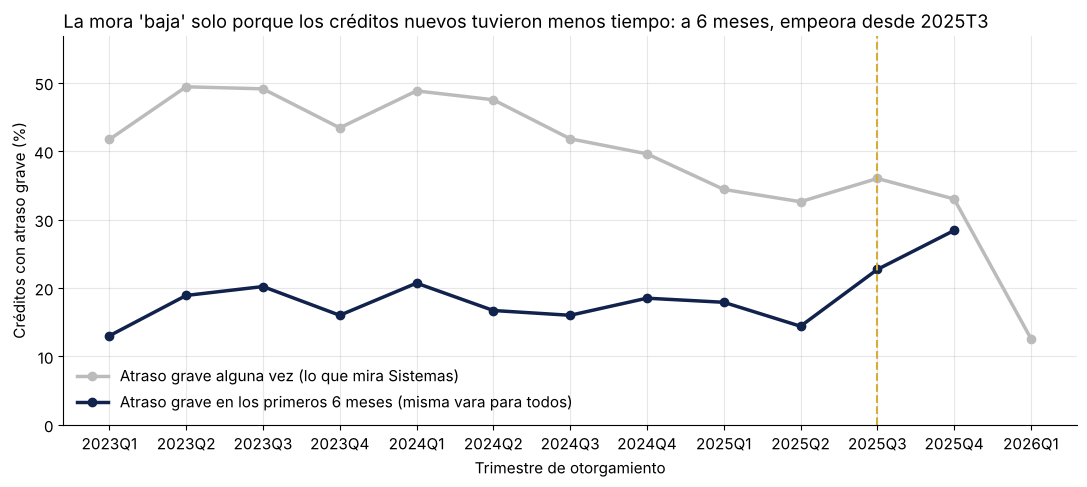

In [58]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    mora_por_trimestre.index,
    mora_por_trimestre["pct_mora_alguna_vez"],
    color=GRIS,
    linewidth=2.5,
    marker="o",
    label="Atraso grave alguna vez (lo que mira Sistemas)",
)
ax.plot(
    mora_por_trimestre.index,
    mora_por_trimestre["pct_mora_6_meses"],
    color=AZUL,
    linewidth=2.5,
    marker="o",
    label="Atraso grave en los primeros 6 meses (misma vara para todos)",
)
ax.axvline("2025Q3", color=DORADO, linestyle="--", linewidth=1.5)
ax.set_title(
    "La mora 'baja' solo porque los créditos nuevos tuvieron menos tiempo: "
    "a 6 meses, empeora desde 2025T3",
    loc="left",
)
ax.set_xlabel("Trimestre de otorgamiento")
ax.set_ylabel("Créditos con atraso grave (%)")
ax.set_ylim(0, mora_por_trimestre["pct_mora_alguna_vez"].max() * 1.15)
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(
    CARPETA_SALIDAS / "mora_por_trimestre.png",
    dpi=RESOLUCION_GRAFICOS,
    bbox_inches="tight",
)
plt.show()

**Conclusión:** la mora "alguna vez" que mira Sistemas baja sola porque los créditos nuevos tuvieron menos tiempo para atrasarse; medida a 6 meses, la cartera estuvo estable hasta 2025T2 y empeora desde 2025T3 (22,7% y 28,4%, los valores más altos de la serie).

In [59]:
# ¿Cambió algo en lo que el banco aprueba? Perfil de originación de cada trimestre
perfil_de_originacion = creditos.groupby("trimestre").agg(
    score_originacion_mediano=("score_originacion", "median"),
    pct_score_menor_a_600=(
        "score_originacion",
        lambda score: round(100 * (score < SCORE_BAJO).mean(), 1),
    ),
    score_clearing_mediano=("score_clearing", "median"),
    ratio_cuota_ingreso_mediano=("ratio_cuota_ingreso", "median"),
    monto_mediano_pesos=("monto_pesos", "median"),
    tasa_mediana=("tasa_nominal_anual", "median"),
    pct_sin_ingreso=("sin_ingreso", calcular_porcentaje),
)
display(perfil_de_originacion.round(3))

# La mezcla de productos y de canales, por trimestre (% de los créditos del trimestre)
display(
    (
        100
        * pd.crosstab(
            creditos["trimestre"], creditos["tipo_producto"], normalize="index"
        )
    ).round(0)
)
display(
    (
        100
        * pd.crosstab(
            creditos["trimestre"], creditos["canal_originacion"], normalize="index"
        )
    ).round(0)
)

,score_originacion_mediano,pct_score_menor_a_600,score_clearing_mediano,ratio_cuota_ingreso_mediano,monto_mediano_pesos,tasa_mediana,pct_sin_ingreso
trimestre,,,,,,,
2023Q1,655.0,23.0,657.0,0.225,153302.020,0.704,4.6
2023Q2,665.5,22.4,663.0,0.237,152053.650,0.700,3.7
2023Q3,666.0,24.6,661.0,0.229,153791.745,0.696,7.2
2023Q4,661.0,26.1,662.0,0.235,156250.980,0.697,3.6
2024Q1,663.0,22.0,663.0,0.243,139367.540,0.706,4.3
2024Q2,657.0,22.9,652.5,0.234,156768.230,0.695,4.8
2024Q3,660.5,22.0,659.0,0.233,141968.870,0.699,4.9
2024Q4,670.5,20.4,670.0,0.224,138551.000,0.707,4.1
2025Q1,675.0,22.9,675.0,0.249,150193.120,0.689,3.3


tipo_producto,Adelanto de sueldo,Crédito hipotecario,Línea de crédito,Préstamo al consumo,Préstamo automotor,Tarjeta de crédito
trimestre,,,,,,
2023Q1,14.0,5.0,10.0,28.0,11.0,32.0
2023Q2,13.0,6.0,10.0,28.0,11.0,33.0
2023Q3,11.0,5.0,9.0,31.0,9.0,36.0
2023Q4,12.0,6.0,10.0,30.0,11.0,32.0
2024Q1,14.0,5.0,8.0,29.0,11.0,33.0
2024Q2,10.0,7.0,8.0,29.0,11.0,35.0
2024Q3,13.0,5.0,9.0,32.0,9.0,32.0
2024Q4,15.0,4.0,9.0,30.0,9.0,34.0
2025Q1,14.0,6.0,8.0,29.0,12.0,32.0


canal_originacion,App,Comercio adherido,Sucursal,Telemarketing,Web
trimestre,,,,,
2023Q1,14.0,21.0,40.0,8.0,18.0
2023Q2,14.0,23.0,41.0,6.0,17.0
2023Q3,15.0,20.0,40.0,10.0,16.0
2023Q4,16.0,21.0,38.0,9.0,16.0
2024Q1,16.0,25.0,37.0,8.0,15.0
2024Q2,14.0,24.0,36.0,9.0,16.0
2024Q3,14.0,21.0,39.0,7.0,19.0
2024Q4,16.0,22.0,40.0,10.0,12.0
2025Q1,12.0,24.0,39.0,10.0,16.0


In [60]:
def calcular_mora_esperada(tabla, tasas_de_referencia, columna_perfil):
    """Devuelve la mora de la tabla si cada perfil tuviera la tasa de referencia."""
    tasas_por_texto = tasas_de_referencia.rename(index=str)
    return tabla[columna_perfil].astype(str).map(tasas_por_texto).astype(float).mean()

In [61]:
# ¿Cuánto del empeoramiento explica la caída del score? Comparo cada tramo de score
# antes y después del quiebre, y calculo la mora que habría tenido el período nuevo
# con su mezcla de scores pero con las tasas de antes
creditos_comparables["tramo_score"] = asignar_tramo(
    serie=creditos_comparables["score_originacion"],
    cortes=TRAMOS_SCORE,
    etiquetas=ETIQUETAS_SCORE,
    etiqueta_faltante=SIN_DATO,
)
creditos_comparables["periodo"] = np.where(
    creditos_comparables["fecha_alta_producto"] >= INICIO_DEL_QUIEBRE,
    "Desde 2025T3",
    "Hasta 2025T2",
)
display(
    creditos_comparables.pivot_table(
        index="tramo_score",
        columns="periodo",
        values="mora_6_meses",
        aggfunc=["size", "mean"],
        observed=True,
    ).round(3)
)

antes_del_quiebre = creditos_comparables[
    creditos_comparables["periodo"] == "Hasta 2025T2"
]
despues_del_quiebre = creditos_comparables[
    creditos_comparables["periodo"] == "Desde 2025T3"
]
mora_antes = antes_del_quiebre["mora_6_meses"].mean()
mora_despues = despues_del_quiebre["mora_6_meses"].mean()
mora_esperada_despues = calcular_mora_esperada(
    tabla=despues_del_quiebre,
    tasas_de_referencia=antes_del_quiebre.groupby("tramo_score", observed=True)[
        "mora_6_meses"
    ].mean(),
    columna_perfil="tramo_score",
)
print(f"Mora a 6 meses hasta 2025T2: {mora_antes:.1%}")
print(f"Mora a 6 meses desde 2025T3: {mora_despues:.1%}")
print(
    f"Mora esperada desde 2025T3 por su mezcla de scores: {mora_esperada_despues:.1%}"
)
print(
    f"Parte del aumento explicada por el score: "
    f"{(mora_esperada_despues - mora_antes) / (mora_despues - mora_antes):.0%}"
)

size                      mean             
periodo      Desde 2025T3 Hasta 2025T2 Desde 2025T3 Hasta 2025T2
tramo_score                                                     
Hasta 550             308          507        0.377        0.337
550 a 600             186          556        0.253        0.250
600 a 650             179          858        0.134        0.182
650 a 700             123         1004        0.236        0.155
Más de 700            104         1486        0.144        0.090
No informado           31          160        0.226        0.212

Mora a 6 meses hasta 2025T2: 17.3%
Mora a 6 meses desde 2025T3: 25.6%
Mora esperada desde 2025T3 por su mezcla de scores: 23.4%
Parte del aumento explicada por el score: 74%


### 3.4 Efecto real o efecto de composición

In [62]:
def comparar_con_lo_esperado(tabla, columna_grupo, casos_minimos):
    """Compara por grupo la mora observada con la esperada por su perfil."""
    resumen = tabla.groupby(columna_grupo).agg(
        creditos=("mora_6_meses", "size"),
        pct_mora_observada=("mora_6_meses", calcular_porcentaje),
        pct_mora_esperada=("mora_esperada_por_perfil", calcular_porcentaje),
    )
    resumen["diferencia_en_puntos"] = (
        resumen["pct_mora_observada"] - resumen["pct_mora_esperada"]
    )
    resumen["pocos_casos"] = resumen["creditos"] < casos_minimos
    return resumen.sort_values("diferencia_en_puntos", ascending=False)

In [63]:
creditos_comparables["perfil"] = (
    creditos_comparables["tramo_score"].astype(str)
    + " | "
    + creditos_comparables["tramo_ratio"].astype(str)
    + " | "
    + creditos_comparables["sector_empleo"]
)
tasas_por_perfil = creditos_comparables.groupby("perfil")["mora_6_meses"].mean()
creditos_comparables["mora_esperada_por_perfil"] = creditos_comparables["perfil"].map(
    tasas_por_perfil
)
print(f"Perfiles distintos con créditos: {len(tasas_por_perfil)}")

efecto_por_canal = comparar_con_lo_esperado(
    tabla=creditos_comparables,
    columna_grupo="canal_originacion",
    casos_minimos=CASOS_MINIMOS_POR_GRUPO,
)
display(efecto_por_canal)

Perfiles distintos con créditos: 144


,creditos,pct_mora_observada,pct_mora_esperada,diferencia_en_puntos,pocos_casos
canal_originacion,,,,,
Comercio adherido,1229,25.3,18.2,7.1,False
Web,883,17.4,19.2,-1.8,False
Sucursal,2131,16.6,18.5,-1.9,False
App,812,16.7,19.0,-2.3,False
Telemarketing,447,16.3,19.1,-2.8,False


In [64]:
# ¿El exceso de Comercio adherido es de un momento o de todo el período?
display(
    creditos_comparables.pivot_table(
        index="canal_originacion",
        columns="periodo",
        values="mora_6_meses",
        aggfunc=calcular_porcentaje,
    )
)

periodo,Desde 2025T3,Hasta 2025T2
canal_originacion,,
App,21.1,15.8
Comercio adherido,36.8,23.1
Sucursal,22.4,15.4
Telemarketing,25.7,14.6
Web,22.4,16.3


In [65]:
efecto_por_departamento = comparar_con_lo_esperado(
    tabla=creditos_comparables,
    columna_grupo="departamento",
    casos_minimos=CASOS_MINIMOS_POR_GRUPO,
)
display(efecto_por_departamento)

# Qué tienen de distinto los clientes de los departamentos con más mora observada
display(
    creditos_comparables.groupby("departamento")
    .agg(
        score_originacion_mediano=("score_originacion", "median"),
        pct_informal_o_independiente=(
            "sector_empleo",
            lambda sector: round(
                100 * sector.isin(["Informal", "Independiente"]).mean(), 1
            ),
        ),
    )
    .loc[["Maldonado", "Treinta y Tres", "Flores", "Florida", "Montevideo"]]
)

,creditos,pct_mora_observada,pct_mora_esperada,diferencia_en_puntos,pocos_casos
departamento,,,,,
Treinta y Tres,70,31.4,20.9,10.5,False
Flores,29,37.9,28.3,9.6,True
Florida,107,24.3,19.6,4.7,False
Tacuarembó,176,22.2,18.3,3.9,False
Rocha,117,20.5,17.1,3.4,False
Salto,254,19.7,18.2,1.5,False
Colonia,171,21.6,20.7,0.9,False
Cerro Largo,132,18.2,17.3,0.9,False
Paysandú,214,16.4,16.3,0.1,False


,score_originacion_mediano,pct_informal_o_independiente
departamento,,
Maldonado,612.0,65.1
Treinta y Tres,653.0,18.6
Flores,594.0,34.5
Florida,658.0,26.2
Montevideo,658.0,16.8


## 4. Visualización

In [66]:
def guardar_grafico(figura, nombre_archivo):
    """Guarda un gráfico de Matplotlib en salidas/ con la resolución del informe."""
    ruta = CARPETA_SALIDAS / nombre_archivo
    figura.savefig(ruta, dpi=RESOLUCION_GRAFICOS, bbox_inches="tight")
    return ruta

### 4.1 Ratio cuota / ingreso contra atraso

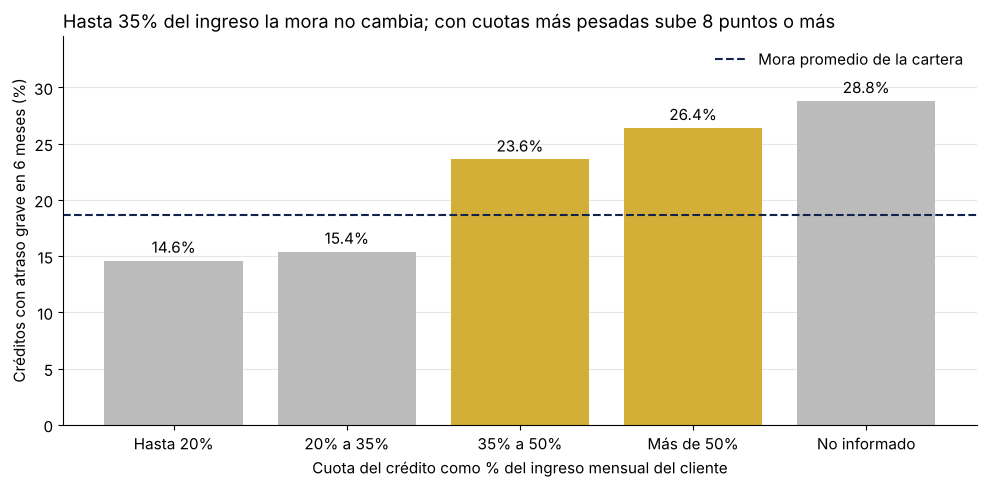

,creditos,pct_mora
tramo_ratio,,
Hasta 20%,2135,14.6
20% a 35%,1408,15.4
35% a 50%,828,23.6
Más de 50%,888,26.4
No informado,243,28.8


In [67]:
mora_por_tramo_de_ratio = creditos_comparables.groupby("tramo_ratio", observed=True)[
    "mora_6_meses"
].agg(creditos="size", pct_mora=calcular_porcentaje)
colores_por_tramo = [
    DORADO if tramo in ["35% a 50%", "Más de 50%"] else GRIS
    for tramo in mora_por_tramo_de_ratio.index
]

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(
    mora_por_tramo_de_ratio.index.astype(str),
    mora_por_tramo_de_ratio["pct_mora"],
    color=colores_por_tramo,
)
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.axhline(
    100 * creditos_comparables["mora_6_meses"].mean(),
    color=AZUL,
    linestyle="--",
    linewidth=1.5,
    label="Mora promedio de la cartera",
)
ax.set_title(
    "Hasta 35% del ingreso la mora no cambia; "
    "con cuotas más pesadas sube 8 puntos o más",
    loc="left",
)
ax.set_xlabel("Cuota del crédito como % del ingreso mensual del cliente")
ax.set_ylabel("Créditos con atraso grave en 6 meses (%)")
ax.set_ylim(0, mora_por_tramo_de_ratio["pct_mora"].max() * 1.2)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
guardar_grafico(fig, "mora_por_ratio_cuota_ingreso.png")
plt.show()
display(mora_por_tramo_de_ratio)

**Conclusión:** con una cuota de hasta el 35% del ingreso la mora queda en 14,6% y 15,4%, debajo del promedio (18,7%); por encima del 35% sube a 23,6% y 26,4%, y por eso la política pone el tope en 35%.

### 4.2 Efecto de composición: el grupo antes y después de controlar por perfil (Plotly)

In [68]:
efecto_canal_para_graficar = (
    efecto_por_canal.reset_index()
    .melt(
        id_vars=["canal_originacion", "creditos", "diferencia_en_puntos"],
        value_vars=["pct_mora_observada", "pct_mora_esperada"],
        var_name="medida",
        value_name="pct_mora",
    )
    .replace(
        {
            "pct_mora_observada": "Observada",
            "pct_mora_esperada": "Esperada por el perfil de sus clientes",
        }
    )
)

figura_composicion = px.bar(
    efecto_canal_para_graficar,
    x="canal_originacion",
    y="pct_mora",
    color="medida",
    barmode="group",
    category_orders={"canal_originacion": efecto_por_canal.index.tolist()},
    color_discrete_sequence=[DORADO, GRIS],
    custom_data=["creditos", "diferencia_en_puntos"],
    labels={
        "canal_originacion": "Canal de originación",
        "pct_mora": "Créditos con atraso grave en 6 meses (%)",
        "medida": "",
    },
    title=(
        "Comercio adherido se atrasa 7 puntos más de lo que explica su perfil: "
        "es un efecto real, no de composición<br>"
        "<sup>Mora observada contra mora esperada por score, ratio cuota / ingreso "
        "y sector. Créditos con 6 meses de exposición.</sup>"
    ),
)
figura_composicion.update_traces(
    hovertemplate=(
        "<b>%{x}</b><br>Mora: %{y:.1f}%<br>"
        "Créditos: %{customdata[0]:,}<br>"
        "Observada menos esperada: %{customdata[1]:+.1f} puntos<extra></extra>"
    )
)
figura_composicion.update_yaxes(rangemode="tozero")
figura_composicion.update_layout(
    height=480, margin={"t": 110}, legend={"orientation": "h"}
)
figura_composicion.write_html(
    CARPETA_SALIDAS / "efecto_composicion_canal.html", include_plotlyjs=True
)
figura_composicion.show()

**Conclusión:** Comercio adherido tiene 25,3% de mora cuando el perfil de sus clientes explica 18,2%: 7,1 puntos de efecto real, mientras los otros canales quedan por debajo de lo esperado.

## 5. Conclusiones y recomendación

### 5.1 Política de crédito: a quién prestar, a quién no y en qué condiciones

In [69]:
creditos_comparables["tiene_garantia"] = creditos_comparables["tipo_producto"].isin(
    PRODUCTOS_CON_GARANTIA
)
display(
    creditos_comparables.pivot_table(
        index="tiene_garantia",
        columns="tramo_ratio",
        values="mora_6_meses",
        aggfunc=calcular_porcentaje,
        observed=True,
    )
)

creditos_sin_garantia = creditos_comparables[~creditos_comparables["tiene_garantia"]]
display(
    creditos_sin_garantia.pivot_table(
        index="tramo_score",
        columns="tramo_ratio",
        values="mora_6_meses",
        aggfunc=calcular_porcentaje,
        observed=True,
    )
)
display(
    pd.crosstab(
        creditos_sin_garantia["tramo_score"], creditos_sin_garantia["tramo_ratio"]
    )
)

tramo_ratio,Hasta 20%,20% a 35%,35% a 50%,Más de 50%,No informado
tiene_garantia,,,,,
False,14.9,16.2,25.0,26.7,29.5
True,8.6,9.6,18.3,25.8,21.7


tramo_ratio,Hasta 20%,20% a 35%,35% a 50%,Más de 50%,No informado
tramo_score,,,,,
Hasta 550,31.0,34.4,40.7,42.0,44.3
550 a 600,23.5,20.2,34.5,31.9,35.7
600 a 650,13.2,14.5,20.6,24.2,26.1
650 a 700,12.1,14.3,25.0,26.4,16.7
Más de 700,7.0,8.1,14.6,16.0,15.2
No informado,17.4,14.0,20.0,39.1,12.5


tramo_ratio,Hasta 20%,20% a 35%,35% a 50%,Más de 50%,No informado
tramo_score,,,,,
Hasta 550,261,180,108,81,61
550 a 600,264,168,87,72,42
600 a 650,379,228,136,99,46
650 a 700,453,252,124,110,30
Más de 700,604,370,178,150,33
No informado,69,43,20,23,8


### 5.2 Qué habría pasado si se aplicaba desde el principio

In [70]:
def marcar_creditos_que_no_se_otorgan(tabla):
    """Devuelve verdadero para los créditos que la política propuesta no otorgaría.

    Los créditos sin score no se marcan: el score faltante es un problema de carga del
    sistema y no del cliente (punto 1.5), así que no se los castiga.
    """
    score = tabla["score_originacion"]
    ratio = tabla["ratio_cuota_ingreso"]
    score_insuficiente = score < SCORE_MINIMO
    cuota_demasiado_pesada = (
        ~tabla["tipo_producto"].isin(PRODUCTOS_CON_GARANTIA)
        & (score < SCORE_SIN_TOPE_DE_CUOTA)
        & (ratio > TOPE_RATIO_CUOTA_INGRESO)
    )
    sin_ingreso_y_score_medio = ratio.isna() & (score < SCORE_MINIMO_SIN_INGRESO)
    return score_insuficiente | cuota_demasiado_pesada | sin_ingreso_y_score_medio


def simular_politica(tabla, no_se_otorga):
    """Compara la cartera real con la que habría quedado aplicando la política."""
    otorgados = tabla[~no_se_otorga]
    rechazados = tabla[no_se_otorga]
    return {
        "creditos_no_otorgados": len(rechazados),
        "pct_creditos_no_otorgados": round(100 * len(rechazados) / len(tabla), 1),
        "mora_actual_pct": round(100 * tabla["mora_6_meses"].mean(), 1),
        "mora_con_politica_pct": round(100 * otorgados["mora_6_meses"].mean(), 1),
        "mora_de_los_no_otorgados_pct": round(
            100 * rechazados["mora_6_meses"].mean(), 1
        ),
        "creditos_en_mora_evitados": int(rechazados["mora_6_meses"].sum()),
        "pct_de_la_mora_evitada": round(
            100 * rechazados["mora_6_meses"].sum() / tabla["mora_6_meses"].sum(), 1
        ),
        "creditos_buenos_perdidos": int((~rechazados["mora_6_meses"]).sum()),
        "pct_del_monto_no_otorgado": round(
            100 * rechazados["monto_pesos"].sum() / tabla["monto_pesos"].sum(), 1
        ),
    }

In [71]:
creditos_comparables["no_se_otorga"] = marcar_creditos_que_no_se_otorgan(
    creditos_comparables
)
efecto_de_la_politica = {
    "Toda la cartera": simular_politica(
        creditos_comparables, creditos_comparables["no_se_otorga"]
    )
}
for periodo_de_otorgamiento in ["Hasta 2025T2", "Desde 2025T3"]:
    creditos_del_periodo = creditos_comparables[
        creditos_comparables["periodo"] == periodo_de_otorgamiento
    ]
    efecto_de_la_politica[periodo_de_otorgamiento] = simular_politica(
        creditos_del_periodo, creditos_del_periodo["no_se_otorga"]
    )
display(pd.DataFrame(efecto_de_la_politica))

,Toda la cartera,Hasta 2025T2,Desde 2025T3
creditos_no_otorgados,1527.0,1056.0,471.0
pct_creditos_no_otorgados,27.8,23.1,50.6
mora_actual_pct,18.7,17.3,25.6
mora_con_politica_pct,13.8,13.2,18.7
mora_de_los_no_otorgados_pct,31.3,30.9,32.3
creditos_en_mora_evitados,478.0,326.0,152.0
pct_de_la_mora_evitada,46.5,41.3,63.9
creditos_buenos_perdidos,1049.0,730.0,319.0
pct_del_monto_no_otorgado,18.6,15.1,34.7


### 5.3 El problema operativo

In [72]:
display(
    calcular_tasa_por_grupo(
        tabla=creditos_comparables[~creditos_comparables["no_se_otorga"]],
        columna_grupo="canal_originacion",
        columna_indicadora="mora_6_meses",
    )
)

,filas,pct
canal_originacion,,
Comercio adherido,907,20.8
App,583,12.5
Web,637,12.4
Telemarketing,326,11.7
Sucursal,1522,11.2


### 5.4 Qué dato adicional le pediríamos al banco

El identificador del comercio adherido de cada crédito, para ver si la mora de ese canal se concentra en algunos comercios.